In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import sys; sys.path.append("..")
from src.calibration import *

PATTERN_SIZE = (8, 5)    # coins INTÉRIEURS (par ligne, par colonne) : à adapter !
SQUARE_SIZE_MM = 29.0    # côté d'une case mesuré à la règle : à adapter !

paths = list_images("../data/calibration")
detections, image_size = detect_corners(paths, PATTERN_SIZE)
save_detection_images(detections, PATTERN_SIZE, "../results/corners")

  img_01.jpg : OK
[!] img_02.jpg : taille 8160x6120 différente de (6120, 8160) -> image ignorée (photo prise en portrait ?)
[!] img_03.jpg : taille 8160x6120 différente de (6120, 8160) -> image ignorée (photo prise en portrait ?)
  img_04.jpg : OK
  img_05.jpg : OK
  img_06.jpg : OK
[!] img_07.jpg : taille 8160x6120 différente de (6120, 8160) -> image ignorée (photo prise en portrait ?)
[!] img_08.jpg : taille 8160x6120 différente de (6120, 8160) -> image ignorée (photo prise en portrait ?)
  img_09.jpg : OK
  img_10.jpg : OK
  img_11.jpg : OK
[!] img_12.jpg : taille 8160x6120 différente de (6120, 8160) -> image ignorée (photo prise en portrait ?)
  img_13.jpg : OK
  img_14.jpg : OK
  img_15.jpg : OK
  img_16.jpg : OK
  img_17.jpg : OK
  img_18.jpg : OK
[!] img_19.jpg : taille 8160x6120 différente de (6120, 8160) -> image ignorée (photo prise en portrait ?)
[!] img_20.jpg : taille 8160x6120 différente de (6120, 8160) -> image ignorée (photo prise en portrait ?)

Damier détecté dans 13/

**Calibration et erreur de retroprojection**

In [3]:
from src.calibration import calibrate, print_calibration, per_image_errors, save_calibration

calib = calibrate(detections, PATTERN_SIZE, SQUARE_SIZE_MM, image_size)
print_calibration(calib)

errors = per_image_errors(calib)
for name, e in sorted(errors.items(), key=lambda x: -x[1]):
    print(f"{name:>12} : {e:.3f} px")

save_calibration(calib, "../results/calibration.json")

Nombre d'images utilisées : 13
Erreur RMS globale        : 2.643 px

Matrice K :
 [[6079.93    0.   3068.47]
 [   0.   6077.81 4077.6 ]
 [   0.      0.      1.  ]]

fx = 6079.9 px   fy = 6077.8 px   fy/fx = 0.9997
cx = 3068.5 px   (centre image : 3060.0, écart +8.5)
cy = 4077.6 px   (centre image : 4080.0, écart -2.4)

Distorsion : k1=0.2901  k2=-1.2969  p1=-0.00197  p2=-0.00106  k3=1.7008
  img_13.jpg : 3.818 px
  img_04.jpg : 3.387 px
  img_17.jpg : 3.313 px
  img_18.jpg : 3.081 px
  img_16.jpg : 2.814 px
  img_09.jpg : 2.704 px
  img_15.jpg : 2.670 px
  img_01.jpg : 2.342 px
  img_14.jpg : 1.892 px
  img_10.jpg : 1.821 px
  img_11.jpg : 1.821 px
  img_06.jpg : 1.767 px
  img_05.jpg : 1.758 px


In [4]:
models = {
    "complet (k1,k2,k3,p1,p2)": 0,
    "sans k3": cv2.CALIB_FIX_K3,
    "k1 seul (comme le cours)": cv2.CALIB_FIX_K2 | cv2.CALIB_FIX_K3 | cv2.CALIB_ZERO_TANGENT_DIST,
}
for name, fl in models.items():
    c = calibrate(detections, PATTERN_SIZE, SQUARE_SIZE_MM, image_size, flags=fl)
    K = c["K"]
    print(f"{name:28s} RMS={c['rms']:.3f}  fx={K[0,0]:.1f}  cx={K[0,2]:.1f}  "
          f"cy={K[1,2]:.1f}  dist={np.round(c['dist'], 4)}")

complet (k1,k2,k3,p1,p2)     RMS=2.643  fx=6079.9  cx=3068.5  cy=4077.6  dist=[ 2.9010e-01 -1.2969e+00 -2.0000e-03 -1.1000e-03  1.7008e+00]
sans k3                      RMS=2.960  fx=6111.1  cx=3071.6  cy=4059.0  dist=[ 0.188  -0.5095 -0.0028 -0.0009  0.    ]
k1 seul (comme le cours)     RMS=5.133  fx=6162.3  cx=3082.9  cy=4080.8  dist=[0.0511 0.     0.     0.     0.    ]


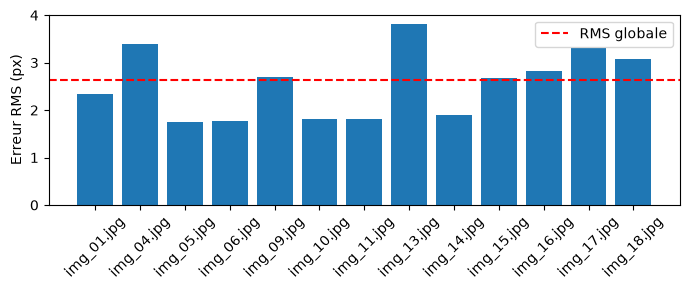

In [5]:
import matplotlib.pyplot as plt
names, vals = zip(*sorted(errors.items()))
plt.figure(figsize=(7, 3)); plt.bar(names, vals); plt.axhline(calib["rms"], ls="--", c="r", label="RMS globale")
plt.ylabel("Erreur RMS (px)"); plt.xticks(rotation=45); plt.legend(); plt.tight_layout()
plt.savefig("../results/erreurs_par_image.png", dpi=200)

In [6]:
print(calib["dist"])

[ 2.90064143e-01 -1.29690584e+00 -1.97131983e-03 -1.06333932e-03
  1.70084570e+00]


**Focale en mm et correction de distorsion**

In [8]:
K, dist = calib["K"], calib["dist"]
pix = 0.8e-3                                  # taille d'un pixel en mm (fiche Samsung)
W_mm, H_mm = 6120 * pix, 8160 * pix           # PORTRAIT : largeur = petit côté du capteur
fovx, fovy, f_mm, pp_mm, aspect = cv2.calibrationMatrixValues(K, image_size, W_mm, H_mm)
print(f"f = {f_mm:.3f} mm | FOV h = {fovx:.1f}°  v = {fovy:.1f}° | aspect = {aspect:.4f}")
print(f"Vérification : f = fx * pix = {K[0,0]*pix:.3f} mm")

img = cv2.imread("../data/calibration/img_13.jpg")
assert img is not None, "Image introuvable : vérifie le chemin"         # une vue inclinée
und = cv2.undistort(img, K, dist)
cv2.imwrite("../results/undistort_img_13.jpg", cv2.resize(und, None, fx=0.15, fy=0.15))

f = 4.864 mm | FOV h = 53.4°  v = 67.7° | aspect = 0.9997
Vérification : f = fx * pix = 4.864 mm


True

In [12]:
from PIL import Image
exif = Image.open("../data/calibration/img_01.jpg").getexif().get_ifd(0x8769)
f_exif = float(exif.get(0x920A))    # FocalLength (mm)
f35 = exif.get(0xA405)              # FocalLengthIn35mmFilm (mm)
print(f"Focale EXIF : {f_exif} mm | équivalent 35 mm : {f35} mm")
print(f"Taille de pixel déduite : f_exif / fx = {f_exif / K[0,0] * 1000:.3f} µm")

Focale EXIF : 4.69 mm | équivalent 35 mm : 25 mm
Taille de pixel déduite : f_exif / fx = 0.771 µm


r max couvert = 0.58 | r coin = 0.84


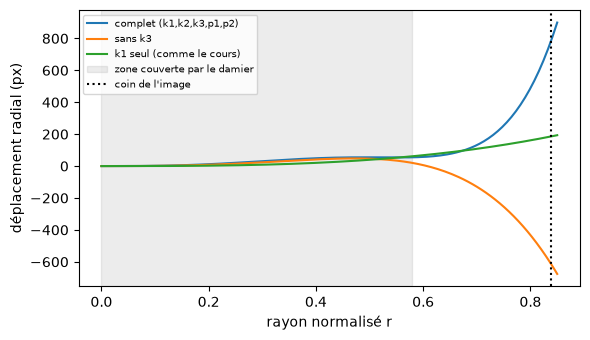

In [13]:
import matplotlib.pyplot as plt
r = np.linspace(0, 0.85, 200)
K0 = calib["K"]
pts = np.vstack([p.reshape(-1, 2) for p in calib["image_points"]])
r_max = np.hypot((pts[:, 0] - K0[0, 2]) / K0[0, 0], (pts[:, 1] - K0[1, 2]) / K0[1, 1]).max()
r_coin = np.hypot(3060 / K0[0, 0], 4080 / K0[1, 1])

plt.figure(figsize=(6, 3.5))
for name, fl in models.items():
    c = calibrate(detections, PATTERN_SIZE, SQUARE_SIZE_MM, image_size, flags=fl)
    k1, k2, p1, p2, k3 = c["dist"]
    plt.plot(r, c["K"][0, 0] * r * (k1*r**2 + k2*r**4 + k3*r**6), label=name)
plt.axvspan(0, r_max, color="grey", alpha=0.15, label="zone couverte par le damier")
plt.axvline(r_coin, ls=":", c="k", label="coin de l'image")
plt.xlabel("rayon normalisé r"); plt.ylabel("déplacement radial (px)")
plt.legend(fontsize=7); plt.tight_layout()
plt.savefig("../results/distorsion_radiale.png", dpi=200)
print(f"r max couvert = {r_max:.2f} | r coin = {r_coin:.2f}")

In [14]:
d = np.array([np.linalg.norm(t) for t in calib["tvecs"]])
print(f"Distance caméra–damier : min {d.min():.0f}, moyenne {d.mean():.0f}, max {d.max():.0f} mm")
z = d.mean()
print(f"z' prédit = {4.69*z/(z-4.69):.3f} mm  (EXIF 4.69, calibration 4.864)")

Distance caméra–damier : min 248, moyenne 303, max 394 mm
z' prédit = 4.764 mm  (EXIF 4.69, calibration 4.864)


Visualisation de la correction de distorsion

In [16]:
def straightness(points, pattern_size):
    """Écart RMS (px) des coins à la droite ajustée sur chaque rangée et colonne."""
    cols, rows = pattern_size
    P = points.reshape(rows, cols, 2)
    res = []
    for line in list(P) + list(P.transpose(1, 0, 2)):
        c = line - line.mean(axis=0)
        _, _, vt = np.linalg.svd(c)          # vt[0] = direction de la droite, vt[1] = normale
        res.append(c @ vt[1])                # distance de chaque coin à la droite
    return float(np.sqrt(np.mean(np.concatenate(res) ** 2)))

K, dist = calib["K"], calib["dist"]
before, after = [], []
for imgp in calib["image_points"]:
    und = cv2.undistortPoints(imgp, K, dist, P=K)      # coins corrigés, en pixels
    before.append(straightness(imgp, PATTERN_SIZE))
    after.append(straightness(und, PATTERN_SIZE))
print(f"Écart moyen à la droite : avant {np.mean(before):.2f} px | après {np.mean(after):.2f} px")

Écart moyen à la droite : avant 2.79 px | après 0.71 px


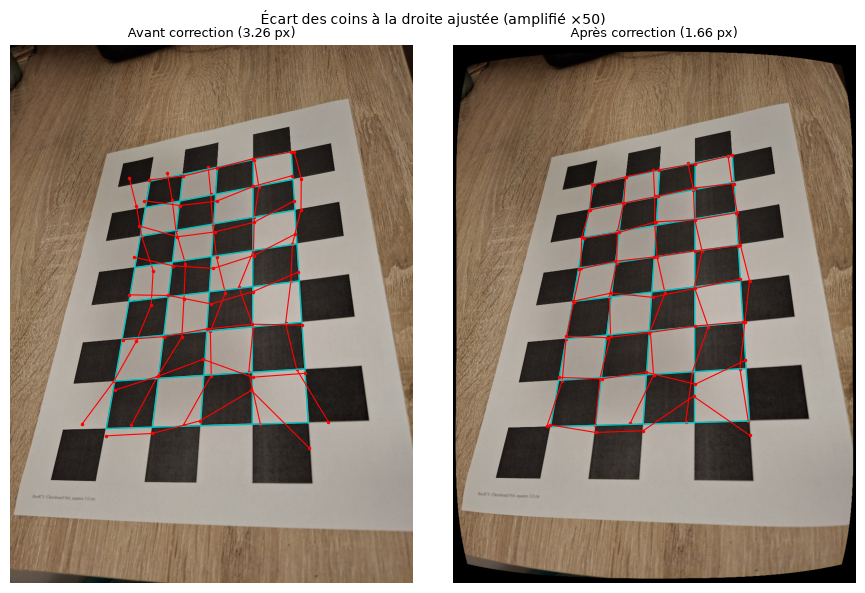

In [17]:
import matplotlib.pyplot as plt

def plot_lines(ax, img, pts, pattern_size, gain=50, title=""):
    """Droite ajustée (cyan) + coins avec écart à la droite amplifié (rouge)."""
    cols, rows = pattern_size
    P = pts.reshape(rows, cols, 2)
    ax.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
    for line in list(P) + list(P.transpose(1, 0, 2)):
        m = line.mean(axis=0)
        c = line - m
        _, _, vt = np.linalg.svd(c)
        d, n = vt[0], vt[1]                      # direction et normale de la droite
        t, e = c @ d, c @ n                      # position le long de la droite, écart
        a, b = m + t.min() * d, m + t.max() * d
        ax.plot([a[0], b[0]], [a[1], b[1]], "c-", lw=1)
        amp = m + np.outer(t, d) + gain * np.outer(e, n)
        ax.plot(amp[:, 0], amp[:, 1], "r.-", ms=3, lw=0.8)
    ax.set_title(title, fontsize=9); ax.axis("off")

name = "img_13.jpg"                                      # une vue inclinée
i = calib["names"].index(name)
img = cv2.imread(f"../data/calibration/{name}")
und_img = cv2.undistort(img, K, dist)
pts = calib["image_points"][i]
und_pts = cv2.undistortPoints(pts, K, dist, P=K)

s = 0.15                                                 # réduction pour l'affichage
small = lambda im: cv2.resize(im, None, fx=s, fy=s)
fig, axes = plt.subplots(1, 2, figsize=(9, 6))
plot_lines(axes[0], small(img), pts * s, PATTERN_SIZE, title=f"Avant correction ({before[i]:.2f} px)")
plot_lines(axes[1], small(und_img), und_pts * s, PATTERN_SIZE, title=f"Après correction ({after[i]:.2f} px)")
fig.suptitle("Écart des coins à la droite ajustée (amplifié ×50)", fontsize=10)
plt.tight_layout(); plt.savefig("../results/droites_avant_apres.png", dpi=200)